# The Signal Desk: arXiv abstract classifier under time shift

**Task.** Read the title and abstract of a computer-science paper and sort it into one of five areas:
`nlp` (cs.CL), `vision` (cs.CV), `security` (cs.CR), `robotics` (cs.RO), `networking` (cs.NI).
The label is the paper's **primary arXiv category**, chosen by its authors.

**Data (collected by `collect_data.py` from the arXiv API).**
* main set: 2,600 papers submitted in **2025**, used for train / validation / test
* stress test: 300 papers submitted in **2012-2014**, same five classes, a different time period

**Three models on the same split, compared by macro-F1:** (A) TF-IDF + logistic regression,
(B) BiLSTM in PyTorch, (C) fine-tuned DistilBERT. Then the stress test, error analysis, the
"I don't know" bonus, and `predict(text)` for the demo.

Run top to bottom. Seeds are fixed to 42. Training time on an RTX 3050 laptop GPU is about 3 minutes
in total (CPU works too, slower).

In [1]:
import os, sys, re, json, time, random
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:  # Colab: mount Drive and open the SignalDesk folder (upload it to My Drive first)
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = next(p for p in [Path("/content/drive/MyDrive/SignalDesk"),
                                   *Path("/content/drive/MyDrive").glob("*/SignalDesk")]
                       if (p / "collect_data.py").exists())
else:
    PROJECT_DIR = Path.cwd()
os.chdir(PROJECT_DIR)
os.environ.setdefault("HF_HUB_DISABLE_XET", "1")      # more reliable HF downloads on slow networks
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
import transformers
transformers.logging.set_verbosity_error(); transformers.logging.disable_progress_bar()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")

MODEL_COLORS = {"A. TF-IDF + LogReg": "#1baf7a", "B. BiLSTM": "#eb6834", "C. DistilBERT": "#2a78d6"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
MODEL_DIR = Path("model")          # best model is saved here (and pushed to the Hub from here)

device: NVIDIA GeForce RTX 3050 Laptop GPU


## 1. Load, clean and explore

Cleaning (Section 1 techniques): strip LaTeX math (`$...$`) and commands (`\emph{}`), URLs and
e-mail-like strings, normalise whitespace. Two versions of the text are kept:

* `text`: lightly cleaned title + abstract, for the Transformer (its own tokenizer handles case)
* `text_norm`: lower-cased, digits replaced by `0`, punctuation removed, for TF-IDF and the BiLSTM

Duplicates are removed on the normalised text and on the normalised title.

In [2]:
def clean(s: str) -> str:
    s = re.sub(r"\$[^$]*\$", " ", s)                      # inline LaTeX math
    s = re.sub(r"\\[a-zA-Z]+\{([^}]*)\}", r"\1", s)        # \emph{x} -> x
    s = re.sub(r"\\[a-zA-Z]+", " ", s)                      # other LaTeX commands
    s = re.sub(r"https?://\S+|www\.\S+|\S+@\S+", " ", s)    # URLs, e-mail-like strings
    return re.sub(r"\s+", " ", s).strip()

def normalise(s: str) -> str:
    s = s.lower()
    s = re.sub(r"\d+", "0", s)
    s = re.sub(r"[^a-z0\s-]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

def prepare(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["text"] = (df["title"].map(clean) + ". " + df["abstract"].map(clean))
    df["text_norm"] = df["text"].map(normalise)
    n0 = len(df)
    df = df.drop_duplicates("arxiv_id").drop_duplicates("text_norm")
    df = df[~df["title"].map(normalise).duplicated()]                 # same title = same paper
    print(f"  {n0} rows -> {len(df)} after removing duplicates")
    return df.reset_index(drop=True)

print("main set:");    main = prepare(pd.read_csv("data/arxiv_main.csv", dtype={"arxiv_id": str}))
print("shifted set:"); shifted = prepare(pd.read_csv("data/arxiv_shifted.csv", dtype={"arxiv_id": str}))
overlap = set(main["text_norm"]) & set(shifted["text_norm"])
print("texts in both sets:", len(overlap))

LABELS = sorted(main["label"].unique())
L2I = {l: i for i, l in enumerate(LABELS)}
main["y"] = main["label"].map(L2I); shifted["y"] = shifted["label"].map(L2I)
print("classes:", LABELS)
main[["published", "label", "text"]].head(3)

main set:


  2600 rows -> 2600 after removing duplicates
shifted set:
  300 rows -> 299 after removing duplicates
texts in both sets: 0
classes: ['networking', 'nlp', 'robotics', 'security', 'vision']


,published,label,text
0,2025-03-31,nlp,Do Chinese models speak Chinese languages?. Th...
1,2025-03-31,nlp,When Do Large Language Models Exhibit Unsolici...
2,2025-03-31,nlp,Text Chunking for Document Classification for ...


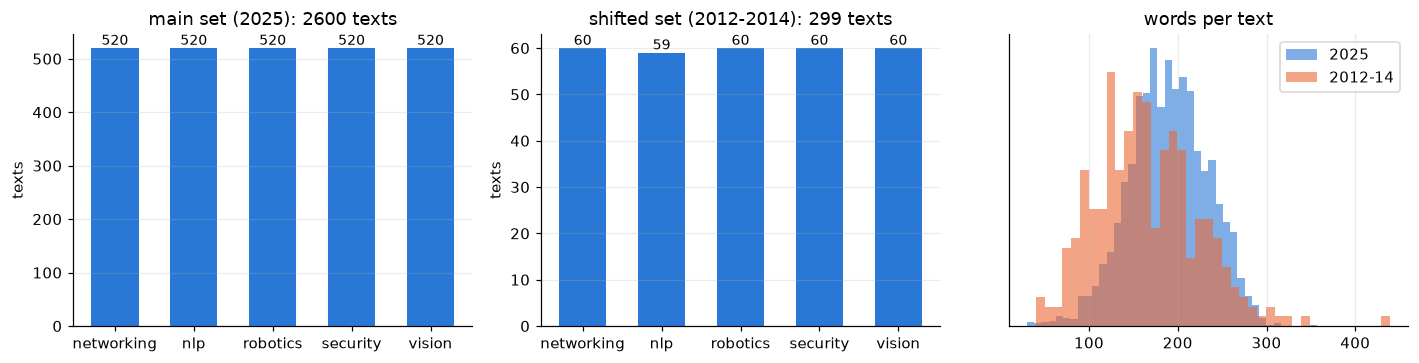

{'count': 2600.0, 'mean': 189.0, 'std': 44.0, 'min': 30.0, '25%': 160.0, '50%': 190.0, '75%': 220.0, 'max': 357.0}


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for a, (name, df) in zip(ax[:2], [("main set (2025)", main), ("shifted set (2012-2014)", shifted)]):
    vc = df["label"].value_counts().reindex(LABELS)
    a.bar(vc.index, vc.values, color="#2a78d6", width=0.6)
    a.set_title(f"{name}: {len(df)} texts"); a.set_ylabel("texts")
    for i, v in enumerate(vc.values): a.text(i, v, str(v), ha="center", va="bottom", fontsize=9)
    a.grid(axis="x", visible=False)
for name, df, c in [("2025", main, "#2a78d6"), ("2012-14", shifted, "#eb6834")]:
    ax[2].hist(df["text_norm"].str.split().map(len), bins=40, alpha=0.6, color=c, label=name, density=True)
ax[2].set_title("words per text"); ax[2].legend(); ax[2].set_yticks([])
plt.tight_layout(); plt.show()
print(main["text_norm"].str.split().map(len).describe().round(0).to_dict())

**Split.** 70 % train, 15 % validation, 15 % test, stratified by class, `random_state=42`.
Validation is used for every choice (C of the logistic regression, LSTM epochs, Transformer epoch,
abstain threshold). Test and the shifted set are only used for the final numbers.

In [4]:
train, tmp = train_test_split(main, test_size=0.30, stratify=main["y"], random_state=SEED)
val, test = train_test_split(tmp, test_size=0.50, stratify=tmp["y"], random_state=SEED)
train, val, test = (d.reset_index(drop=True) for d in (train, val, test))
assert not (set(train.arxiv_id) & set(val.arxiv_id) | set(train.arxiv_id) & set(test.arxiv_id))
print({n: len(d) for n, d in [("train", train), ("val", val), ("test", test), ("shifted", shifted)]})

RESULTS = {}     # model -> dict of metrics
PROBS = {}       # model -> {split: probability matrix}
def evaluate(name, probs_by_split, extra=None):
    PROBS[name] = probs_by_split
    row = {}
    for split, df in [("val", val), ("test", test), ("shifted", shifted)]:
        pred = probs_by_split[split].argmax(1)
        row[f"{split}_macroF1"] = f1_score(df["y"], pred, average="macro")
        row[f"{split}_acc"] = accuracy_score(df["y"], pred)
    RESULTS[name] = {**row, **(extra or {})}
    print(f"{name}: val F1 {row['val_macroF1']:.3f} | test F1 {row['test_macroF1']:.3f} | "
          f"shifted F1 {row['shifted_macroF1']:.3f}")

{'train': 1820, 'val': 390, 'test': 390, 'shifted': 299}


## 2. Model A: classical baseline (TF-IDF + logistic regression)

Word unigrams + bigrams, English stop words removed, sub-linear TF, terms that appear in at least
2 training texts. The regularisation strength `C` is picked on validation macro-F1.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

t0 = time.time()
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, stop_words="english")
Xtr = tfidf.fit_transform(train["text_norm"])
Xva, Xte, Xsh = (tfidf.transform(d["text_norm"]) for d in (val, test, shifted))
print("vocabulary size:", len(tfidf.vocabulary_))

search = {}
for C in [0.5, 1, 2, 4, 8, 16, 32]:
    clf = LogisticRegression(C=C, max_iter=3000, random_state=SEED).fit(Xtr, train["y"])
    search[C] = f1_score(val["y"], clf.predict(Xva), average="macro")
best_C = max(search, key=search.get)
print("val macro-F1 by C:", {c: round(v, 3) for c, v in search.items()}, "-> C =", best_C)
logreg = LogisticRegression(C=best_C, max_iter=3000, random_state=SEED).fit(Xtr, train["y"])
evaluate("A. TF-IDF + LogReg",
         {"val": logreg.predict_proba(Xva), "test": logreg.predict_proba(Xte), "shifted": logreg.predict_proba(Xsh)},
         {"train_seconds": round(time.time() - t0, 1), "params": logreg.coef_.size + logreg.intercept_.size})

terms = np.array(tfidf.get_feature_names_out())
print("\nstrongest words per class:")
for i, l in enumerate(LABELS):
    print(f"  {l:11s}", ", ".join(terms[np.argsort(logreg.coef_[i])[::-1][:10]]))

vocabulary size: 27172


val macro-F1 by C: {0.5: 0.911, 1: 0.913, 2: 0.924, 4: 0.929, 8: 0.929, 16: 0.931, 32: 0.934} -> C = 32


A. TF-IDF + LogReg: val F1 0.934 | test F1 0.915 | shifted F1 0.896

strongest words per class:
  networking  network, networks, wireless, traffic, networking, 0g, communication, service, internet, ran
  nlp         llms, language, language models, large language, models, text, languages, models llms, english, scientific
  robotics    robot, robotic, robots, control, manipulation, planning, robotics, navigation, simulation, motion
  security    security, attacks, attack, privacy, vulnerability, malicious, vulnerabilities, threat, cybersecurity, secure
  vision      image, visual, images, video, vision, 0d, segmentation, object, spatial, diffusion


## 3. Model B: BiLSTM (PyTorch)

Vocabulary from the training texts (words seen at least twice), sequences cut at 300 words.
Embedding 128 -> 1-layer bidirectional LSTM (128 per direction, packed sequences so padding is
ignored) -> max + mean pooling -> dropout -> linear. Adam, up to 15 epochs, early stopping on
validation macro-F1 (patience 3); the best epoch's weights are kept.

In [6]:
import torch.nn as nn
from collections import Counter
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

MAX_LEN = 300
counts = Counter(w for t in train["text_norm"] for w in t.split())
itos = ["<pad>", "<unk>"] + [w for w, c in counts.most_common() if c >= 2]
stoi = {w: i for i, w in enumerate(itos)}
print("LSTM vocabulary:", len(itos))

def encode(texts):
    ids = [[stoi.get(w, 1) for w in t.split()[:MAX_LEN]] or [1] for t in texts]
    lens = torch.tensor([len(x) for x in ids])
    out = torch.zeros(len(ids), lens.max(), dtype=torch.long)
    for i, x in enumerate(ids): out[i, :len(x)] = torch.tensor(x)
    return out, lens

class BiLSTM(nn.Module):
    def __init__(self, vocab, n_cls, emb=128, hid=128, drop=0.4):
        super().__init__()
        self.emb = nn.Embedding(vocab, emb, padding_idx=0)
        self.lstm = nn.LSTM(emb, hid, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(drop)
        self.fc = nn.Linear(4 * hid, n_cls)
    def forward(self, x, lens):
        e = self.drop(self.emb(x))
        out, _ = self.lstm(pack_padded_sequence(e, lens.cpu(), batch_first=True, enforce_sorted=False))
        out, _ = pad_packed_sequence(out, batch_first=True)
        mask = (torch.arange(out.size(1), device=x.device)[None] < lens.to(x.device)[:, None]).unsqueeze(-1)
        mx = out.masked_fill(~mask, -1e4).max(1).values
        mean = (out * mask).sum(1) / lens.to(x.device)[:, None]
        return self.fc(self.drop(torch.cat([mx, mean], 1)))

def lstm_probs(model, df, bs=128):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(df), bs):
            x, l = encode(df["text_norm"].iloc[i:i + bs])
            out.append(torch.softmax(model(x.to(DEVICE), l), 1).cpu())
    return torch.cat(out).numpy()

set_seed()
lstm = BiLSTM(len(itos), len(LABELS)).to(DEVICE)
opt = torch.optim.Adam(lstm.parameters(), lr=2e-3)
lossf = nn.CrossEntropyLoss()
best_f1, best_state, wait, history = -1, None, 0, []
t0 = time.time()
for epoch in range(1, 16):
    lstm.train()
    order = np.random.permutation(len(train))
    for i in range(0, len(order), 32):
        b = train.iloc[order[i:i + 32]]
        x, l = encode(b["text_norm"])
        loss = lossf(lstm(x.to(DEVICE), l), torch.tensor(b["y"].values, device=DEVICE))
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(lstm.parameters(), 1.0); opt.step()
    f1 = f1_score(val["y"], lstm_probs(lstm, val).argmax(1), average="macro")
    history.append(f1); print(f"  epoch {epoch:2d}  last batch loss {loss.item():.3f}  val macro-F1 {f1:.3f}")
    if f1 > best_f1:
        best_f1, best_state, wait = f1, {k: v.detach().clone() for k, v in lstm.state_dict().items()}, 0
    else:
        wait += 1
        if wait >= 3: print("  early stop"); break
lstm.load_state_dict(best_state)
evaluate("B. BiLSTM", {s: lstm_probs(lstm, d) for s, d in [("val", val), ("test", test), ("shifted", shifted)]},
         {"train_seconds": round(time.time() - t0, 1), "params": sum(p.numel() for p in lstm.parameters()),
          "best_epoch": int(np.argmax(history)) + 1})

LSTM vocabulary: 11876


  epoch  1  last batch loss 1.566  val macro-F1 0.364


  epoch  2  last batch loss 0.941  val macro-F1 0.572


  epoch  3  last batch loss 0.736  val macro-F1 0.703


  epoch  4  last batch loss 0.404  val macro-F1 0.769


  epoch  5  last batch loss 0.493  val macro-F1 0.777


... (6 outputs left out)

  epoch 12  last batch loss 0.032  val macro-F1 0.871


  epoch 13  last batch loss 0.009  val macro-F1 0.868


  epoch 14  last batch loss 0.046  val macro-F1 0.843
  early stop


B. BiLSTM: val F1 0.882 | test F1 0.877 | shifted F1 0.823


## 4. Model C: fine-tuned Transformer (DistilBERT)

`distilbert-base-uncased` (66 M parameters) with a classification head, on the lightly cleaned
text, max 256 tokens. AdamW, learning rate 5e-5, linear warm-up/decay, batch 16, 3 epochs, mixed
precision on GPU. The epoch with the best validation macro-F1 is kept.

In [7]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

BASE = "distilbert-base-uncased"
tok = AutoTokenizer.from_pretrained(BASE)
set_seed()
bert = AutoModelForSequenceClassification.from_pretrained(
    BASE, num_labels=len(LABELS), id2label=dict(enumerate(LABELS)), label2id=L2I).to(DEVICE)

def batches(df, bs, shuffle=False):
    idx = np.random.permutation(len(df)) if shuffle else np.arange(len(df))
    for i in range(0, len(idx), bs):
        b = df.iloc[idx[i:i + bs]]
        enc = tok(list(b["text"]), truncation=True, max_length=256, padding=True, return_tensors="pt")
        yield {k: v.to(DEVICE) for k, v in enc.items()}, torch.tensor(b["y"].values, device=DEVICE)

def bert_probs(df, bs=64):
    bert.eval(); out = []
    with torch.no_grad(), torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
        for enc, _ in batches(df, bs):
            out.append(torch.softmax(bert(**enc).logits.float(), 1).cpu())
    return torch.cat(out).numpy()

EPOCHS, BS = 3, 16
opt = torch.optim.AdamW(bert.parameters(), lr=5e-5, weight_decay=0.01)
steps = EPOCHS * int(np.ceil(len(train) / BS))
sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
scaler = torch.amp.GradScaler(enabled=DEVICE == "cuda")
best_f1, wait = -1, 0
t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    bert.train()
    for enc, y in batches(train, BS, shuffle=True):
        with torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
            loss = bert(**enc, labels=y).loss
        opt.zero_grad(); scaler.scale(loss).backward(); scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(bert.parameters(), 1.0); scaler.step(opt); scaler.update(); sched.step()
    f1 = f1_score(val["y"], bert_probs(val).argmax(1), average="macro")
    print(f"  epoch {epoch}  last batch loss {loss.item():.3f}  val macro-F1 {f1:.3f}  ({time.time() - t0:.0f} s)")
    if f1 > best_f1:
        best_f1, best_epoch = f1, epoch
        bert.save_pretrained(MODEL_DIR); tok.save_pretrained(MODEL_DIR)
bert_seconds = round(time.time() - t0, 1)
bert = AutoModelForSequenceClassification.from_pretrained(MODEL_DIR).to(DEVICE)
evaluate("C. DistilBERT", {s: bert_probs(d) for s, d in [("val", val), ("test", test), ("shifted", shifted)]},
         {"train_seconds": bert_seconds, "params": sum(p.numel() for p in bert.parameters()), "best_epoch": best_epoch})
if DEVICE == "cuda": print(f"peak GPU memory {torch.cuda.max_memory_allocated() / 1e9:.2f} GB")

  epoch 1  last batch loss 0.198  val macro-F1 0.878  (20 s)


  epoch 2  last batch loss 0.529  val macro-F1 0.911  (41 s)


  epoch 3  last batch loss 0.025  val macro-F1 0.924  (61 s)


C. DistilBERT: val F1 0.924 | test F1 0.913 | shifted F1 0.947
peak GPU memory 2.10 GB


## 5. Results and the stress test

Same split for all three models. The shifted set is 300 papers from **2012-2014**: same five
categories, but written ten years earlier, before transformers, LLMs, diffusion models and most of
today's vocabulary existed.

,val macro-F1,test macro-F1 (2025),shifted macro-F1 (2012-14),drop (F1 points),relative drop %,test acc,shifted acc,parameters,train time (s)
A. TF-IDF + LogReg,0.934,0.915,0.896,1.9,2.1,0.915,0.896,"135,865",6.2
B. BiLSTM,0.882,0.877,0.823,5.5,6.2,0.877,0.823,"1,786,885",46.4
C. DistilBERT,0.924,0.913,0.947,-3.4,-3.7,0.913,0.946,"66,957,317",61.6


|                    |   val macro-F1 |   test macro-F1 (2025) |   shifted macro-F1 (2012-14) |   drop (F1 points) |   relative drop % |
|:-------------------|---------------:|-----------------------:|-----------------------------:|-------------------:|------------------:|
| A. TF-IDF + LogReg |          0.934 |                  0.915 |                        0.896 |              1.929 |             2.108 |
| B. BiLSTM          |          0.882 |                  0.877 |                        0.823 |              5.46  |             6.224 |
| C. DistilBERT      |          0.924 |                  0.913 |                        0.947 |             -3.408 |            -3.733 |


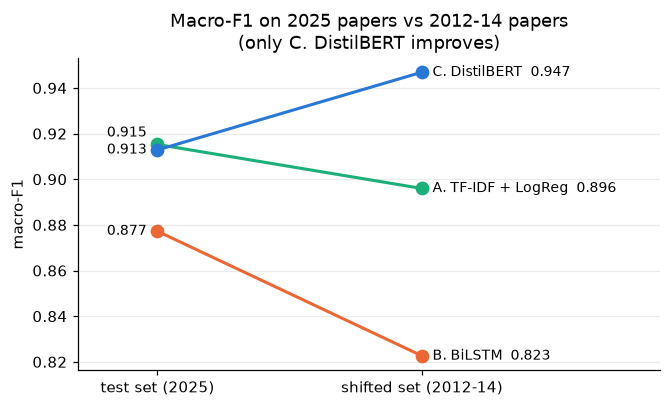

In [8]:
res = pd.DataFrame(RESULTS).T
res["drop (F1 points)"] = 100 * (res["test_macroF1"] - res["shifted_macroF1"])
res["relative drop %"] = 100 * (1 - res["shifted_macroF1"] / res["test_macroF1"])
table = res[["val_macroF1", "test_macroF1", "shifted_macroF1", "drop (F1 points)", "relative drop %",
             "test_acc", "shifted_acc", "params", "train_seconds"]].astype(float)
table.columns = ["val macro-F1", "test macro-F1 (2025)", "shifted macro-F1 (2012-14)", "drop (F1 points)",
                 "relative drop %", "test acc", "shifted acc", "parameters", "train time (s)"]
display(table.style.format({c: "{:.3f}" for c in table.columns[:3]} |
                           {"drop (F1 points)": "{:.1f}", "relative drop %": "{:.1f}", "test acc": "{:.3f}",
                            "shifted acc": "{:.3f}", "parameters": "{:,.0f}", "train time (s)": "{:.1f}"}))
print(table.iloc[:, :5].round(3).to_markdown())

def spread(vals, gap):  # nudge label positions apart so they never overlap
    order, out, last = np.argsort(vals), np.array(vals, float), -np.inf
    for i in order:
        out[i] = max(out[i], last + gap); last = out[i]
    return out

fig, ax = plt.subplots(figsize=(6.2, 3.8))
gap = 0.06 * np.ptp(res[["test_macroF1", "shifted_macroF1"]].values)
ly, ry = spread(res.test_macroF1.values, gap), spread(res.shifted_macroF1.values, gap)
for k, (name, r) in enumerate(res.iterrows()):
    c = MODEL_COLORS[name]
    ax.plot([0, 1], [r.test_macroF1, r.shifted_macroF1], color=c, lw=2, marker="o", ms=8)
    ax.text(1.04, ry[k], f"{name}  {r.shifted_macroF1:.3f}", va="center", fontsize=9)
    ax.text(-0.04, ly[k], f"{r.test_macroF1:.3f}", va="center", ha="right", fontsize=9)
ax.set_xticks([0, 1], ["test set (2025)", "shifted set (2012-14)"]); ax.set_xlim(-0.3, 1.9)
up = res.index[res.shifted_macroF1 > res.test_macroF1].tolist()
ax.set_ylabel("macro-F1"); ax.grid(axis="x", visible=False)
ax.set_title("Macro-F1 on 2025 papers vs 2012-14 papers" + (f"\n(only {', '.join(up)} improves)" if up else ""))
plt.tight_layout(); plt.show()

**Why did the scores move?** Two measurable differences between the 2025 test set and the
2012-14 set: how many words the models have never seen in training (out-of-vocabulary rate for the
BiLSTM's vocabulary), and how often papers outside `nlp` talk about language models, the topic that
blurs the class boundaries in 2025.

In [9]:
def oov_rate(df):
    toks = [w for t in df["text_norm"] for w in t.split()[:MAX_LEN]]
    return np.mean([w not in stoi for w in toks])

llm_pat = r"\bllms?\b|language models?\b|\bgpt\b|chatgpt"
for name, df in [("test (2025)", test), ("shifted (2012-14)", shifted)]:
    non_nlp = df[df["label"] != "nlp"]
    print(f"{name:18s} BiLSTM out-of-vocabulary words {100 * oov_rate(df):4.1f} %  |  non-nlp papers that "
          f"mention LLMs / language models {100 * non_nlp['text_norm'].str.contains(llm_pat).mean():4.1f} %")

test (2025)        BiLSTM out-of-vocabulary words  6.5 %  |  non-nlp papers that mention LLMs / language models 20.5 %
shifted (2012-14)  BiLSTM out-of-vocabulary words  6.0 %  |  non-nlp papers that mention LLMs / language models  0.0 %


**Which model dropped the most and why.** The BiLSTM dropped the most (0.877 → 0.823, −5.5 F1 points);
TF-IDF dropped 1.9 points and DistilBERT *rose* 3.4 points. It is **not** because of unseen words: the
BiLSTM's out-of-vocabulary rate is about the same on both sets (6.5 % vs 6.0 %). The more likely cause
is that the BiLSTM learned its word meanings from only 1,820 abstracts with no pre-training, so it leans
on 2025-specific topic cues and wording, while DistilBERT brings general English knowledge from
pre-training and TF-IDF only needs a few strong keywords (*robot*, *attack*, *wireless*) that are stable
over time. The 2012-14 set is also *easier* in one measurable way: 20.5 % of non-NLP 2025 papers talk
about LLMs, against 0 % in 2012-14, and that overlap caused most 2025 errors (see section 6).
With 299 shifted texts, differences of about ±3 points are within noise.

**Which model is "best"?** Before picking, check whether the gap between the top two on the 2025 test
set is real: a paired bootstrap (2,000 resamples of the 390 test texts) gives a 95 % interval for the
macro-F1 difference. If the interval contains 0 the two are tied on the original test set, and the
tie is broken by robustness on the shifted set, which is what the Signal Desk is about.

In [10]:
rng = np.random.default_rng(SEED)
ranked = res["test_macroF1"].sort_values(ascending=False).index[:2]
pa, pb = (PROBS[m]["test"].argmax(1) for m in ranked)
yt = test["y"].values
diffs = []
for _ in range(2000):
    i = rng.integers(0, len(yt), len(yt))
    diffs.append(f1_score(yt[i], pa[i], average="macro") - f1_score(yt[i], pb[i], average="macro"))
lo, hi = np.percentile(diffs, [2.5, 97.5])
tied = lo <= 0 <= hi
print(f"test macro-F1 {ranked[0]} minus {ranked[1]}: {res.loc[ranked[0], 'test_macroF1'] - res.loc[ranked[1], 'test_macroF1']:+.3f}"
      f"  (95 % bootstrap interval {lo:+.3f} to {hi:+.3f}) -> {'tied' if tied else 'real difference'}")
BEST = (max(ranked, key=lambda m: res.loc[m, "shifted_macroF1"]) if tied else ranked[0])
print("best model:", BEST, "(higher shifted-set macro-F1)" if tied else "")

test macro-F1 A. TF-IDF + LogReg minus C. DistilBERT: +0.002  (95 % bootstrap interval -0.030 to +0.035) -> tied
best model: C. DistilBERT (higher shifted-set macro-F1)


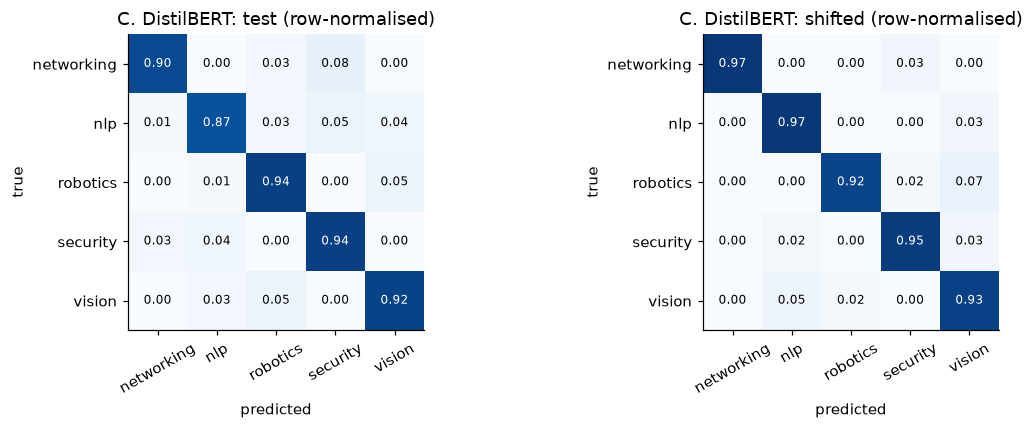

              precision    recall  f1-score   support

  networking      1.000     0.967     0.983        60
         nlp      0.934     0.966     0.950        59
    robotics      0.982     0.917     0.948        60
    security      0.950     0.950     0.950        60
      vision      0.875     0.933     0.903        60

    accuracy                          0.946       299
   macro avg      0.948     0.947     0.947       299
weighted avg      0.948     0.946     0.947       299



In [11]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for a, (split, df) in zip(axs, [("test", test), ("shifted", shifted)]):
    cm = confusion_matrix(df["y"], PROBS[BEST][split].argmax(1), normalize="true")
    a.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(LABELS)):
        for j in range(len(LABELS)):
            a.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8,
                   color="white" if cm[i, j] > 0.6 else "black")
    a.set_xticks(range(len(LABELS)), LABELS, rotation=30); a.set_yticks(range(len(LABELS)), LABELS)
    a.set_xlabel("predicted"); a.set_ylabel("true"); a.set_title(f"{BEST}: {split} (row-normalised)"); a.grid(False)
plt.tight_layout(); plt.show()
print(classification_report(shifted["y"], PROBS[BEST]["shifted"].argmax(1), target_names=LABELS, digits=3))

## 6. Error analysis: 10 test texts the best model got wrong

The ten **most confident** mistakes on the original test set (most confident first), because
confident mistakes are the ones a user would trust.

In [12]:
p = PROBS[BEST]["test"]
wrong = test.assign(pred=[LABELS[i] for i in p.argmax(1)], confidence=p.max(1),
                    p_true=p[np.arange(len(test)), test["y"]])
wrong = wrong[wrong["pred"] != wrong["label"]].sort_values("confidence", ascending=False)
print(f"{len(wrong)} of {len(test)} test texts wrong")
pd.set_option("display.max_colwidth", 140)
errors = wrong.head(10)[["arxiv_id", "label", "pred", "confidence", "p_true", "title"]].reset_index(drop=True)
errors.index += 1
errors.round(3)

34 of 390 test texts wrong


,arxiv_id,label,pred,confidence,p_true,title
1,2512.21723,robotics,nlp,0.991,0.002,HELP: Hierarchical Embodied Language Planner for Household Tasks
2,2510.02342,security,nlp,0.990,0.005,CATMark: A Context-Aware Thresholding Framework for Robust Cross-Task Watermarking in Large Language Models
3,2503.18487,networking,security,0.986,0.006,"Large Language Models powered Malicious Traffic Detection: Architecture, Opportunities and Case Study"
4,2506.24068,nlp,security,0.985,0.004,STACK: Adversarial Attacks on LLM Safeguard Pipelines
5,2503.23660,vision,nlp,0.985,0.007,"DeepDubber-V1: Towards High Quality and Dialogue, Narration, Monologue Adaptive Movie Dubbing Via Multi-Modal Chain-of-Thoughts Reasonin..."
6,2509.10214,networking,security,0.985,0.008,Friend or Foe? Identifying Anomalous Peers in Moneros P2P Network
7,2509.25568,nlp,vision,0.984,0.005,Probing the Limits of Stylistic Alignment in Vision-Language Models
8,2512.02272,networking,security,0.984,0.008,Intrusion Detection on Resource-Constrained IoT Devices with Hardware-Aware ML and DL
9,2510.00311,nlp,security,0.983,0.007,CORTEX: Collaborative LLM Agents for High-Stakes Alert Triage
10,2509.09453,networking,security,0.980,0.012,"Toward quantum-safe scalable networks: an open, standards-aware key management framework"


**Why each one failed (my reading of the title and abstract, for the saved run above):**

| # | true → predicted | one-line guess |
|---|---|---|
| 1 | robotics → nlp | an LLM-based task planner: the abstract is mostly language-model vocabulary, the robot is only the application |
| 2 | security → nlp | watermarking LLM output sits between both fields; the text describes text generation more than attacks |
| 3 | networking → security | "malicious traffic detection" is security vocabulary; the authors filed it under networking |
| 4 | nlp → security | an adversarial-attack paper; the model's answer is defensible, the label is the authors' choice |
| 5 | vision → nlp | movie dubbing with dialogue, narration and chain-of-thought: the words are about speech and language |
| 6 | networking → security | anomalous peers in a cryptocurrency P2P network: "foe", "anomalous", "Monero" read as security |
| 7 | nlp → vision | "vision-language models" in the title pulls it to vision although it studies text style |
| 8 | networking → security | intrusion detection is a classic security topic, even on IoT networks |
| 9 | nlp → security | LLM agents for security-alert triage: the domain words (alerts, SOC, threats) dominate |
| 10 | networking → security | quantum-safe key management is cryptography; networking is only the setting |

**Pattern:** all ten are papers that genuinely sit between two areas, and 7 of 10 involve `security`.
The label is the area the authors chose as primary, so many of these are not really model errors.
A multi-label setup (arXiv's cross-lists) would describe these papers better than one class.

## 7. Bonus: an "I don't know" option

If the top confidence is below a threshold `t`, the desk abstains instead of answering. `t` is
chosen on **validation only**: the largest value that still answers at least 90 % of validation
texts. Then on the shifted set we compare precision (accuracy of the answers given) with and without
abstaining.

|                                   |   threshold |   precision (always answer) |   precision (with abstain) |   coverage |   abstained |
|:----------------------------------|------------:|----------------------------:|---------------------------:|-----------:|------------:|
| ('A. TF-IDF + LogReg', 'test')    |       0.598 |                       0.915 |                      0.953 |      0.867 |          52 |
| ('A. TF-IDF + LogReg', 'shifted') |       0.598 |                       0.896 |                      0.958 |      0.799 |          60 |
| ('B. BiLSTM', 'test')             |       0.805 |                       0.877 |                      0.932 |      0.903 |          38 |
| ('B. BiLSTM', 'shifted')          |       0.805 |                       0.823 |                      0.864 |      0.886 |          34 |
| ('C. DistilBERT', 'test')         |       0.901 |                       0.913 |                      0.938 |      0.913 |          34 |
| ('C. DistilBERT', 'shifted')    

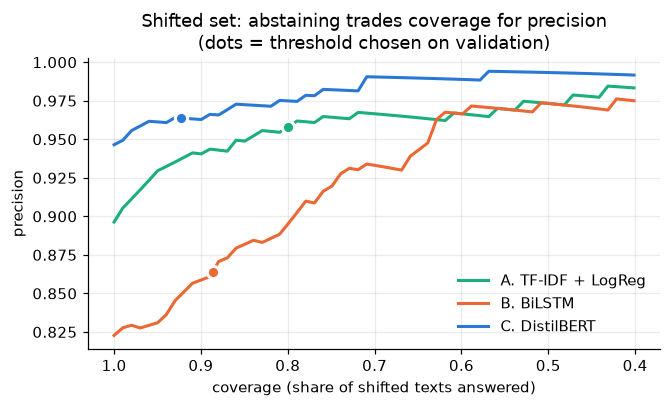

In [13]:
def abstain_stats(probs, y, t):
    conf, pred = probs.max(1), probs.argmax(1)
    keep = conf >= t
    return {"coverage": keep.mean(), "precision": (pred[keep] == y[keep]).mean() if keep.any() else np.nan,
            "macroF1 answered": f1_score(y[keep], pred[keep], average="macro") if keep.any() else np.nan}

rows, THRESH = [], {}
for name in RESULTS:
    vconf = PROBS[name]["val"].max(1)
    t = float(np.quantile(vconf, 0.10))                    # answers 90 % of validation texts
    THRESH[name] = t
    for split, df in [("test", test), ("shifted", shifted)]:
        base = abstain_stats(PROBS[name][split], df["y"].values, 0.0)
        ab = abstain_stats(PROBS[name][split], df["y"].values, t)
        rows.append({"model": name, "set": split, "threshold": t, "precision (always answer)": base["precision"],
                     "precision (with abstain)": ab["precision"], "coverage": ab["coverage"],
                     "abstained": int(round((1 - ab["coverage"]) * len(df)))})
abst = pd.DataFrame(rows).set_index(["model", "set"])
display(abst.style.format({"threshold": "{:.3f}", "precision (always answer)": "{:.3f}",
                           "precision (with abstain)": "{:.3f}", "coverage": "{:.1%}"}))
print(abst.round(3).to_markdown())

fig, ax = plt.subplots(figsize=(6.2, 3.8))
for name in RESULTS:
    pr, y = PROBS[name]["shifted"], shifted["y"].values
    ts = np.unique(np.quantile(pr.max(1), np.linspace(0, 0.6, 61)))
    st = [abstain_stats(pr, y, t) for t in ts]
    ax.plot([s["coverage"] for s in st], [s["precision"] for s in st], color=MODEL_COLORS[name], lw=2, label=name)
    s = abstain_stats(pr, y, THRESH[name])
    ax.plot(s["coverage"], s["precision"], "o", ms=8, color=MODEL_COLORS[name], mec="white", mew=2)
ax.invert_xaxis(); ax.set_xlabel("coverage (share of shifted texts answered)"); ax.set_ylabel("precision")
ax.set_title("Shifted set: abstaining trades coverage for precision\n(dots = threshold chosen on validation)")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

## 8. Save, `predict(text)` and the Hugging Face Hub

The best DistilBERT checkpoint is saved in `model/` with its tokenizer. `model/signal_desk.json`
stores the label list and the abstain threshold, which `app.py` and the Space use.

Published model: https://huggingface.co/pradeepkumawat/signal-desk-distilbert ·
demo: https://huggingface.co/spaces/pradeepkumawat/signal-desk

The upload cell runs only when `PUSH_TO_HUB = True`.
- It reads the access token from the `HF_TOKEN` environment variable, so no token appears in the
  code.
- It reads the repo name from `HF_REPO_ID`.
- If `export_onnx.py` has been run, the ONNX files in `model/onnx/` are uploaded too.

In [14]:
json.dump({"labels": LABELS, "abstain_threshold": THRESH["C. DistilBERT"], "base_model": BASE,
           "test_macroF1": float(RESULTS["C. DistilBERT"]["test_macroF1"]),
           "shifted_macroF1": float(RESULTS["C. DistilBERT"]["shifted_macroF1"])},
          open(MODEL_DIR / "signal_desk.json", "w"), indent=2)

def predict(text: str, k: int = 3) -> dict:
    """Top-k classes with confidence for one text (DistilBERT). Abstains below the validation threshold."""
    bert.eval()
    enc = tok(clean(text), truncation=True, max_length=256, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        pr = torch.softmax(bert(**enc).logits.float(), 1)[0].cpu().numpy()
    top = np.argsort(pr)[::-1][:k]
    best = float(pr[top[0]])
    return {"top": [(LABELS[i], round(float(pr[i]), 3)) for i in top],
            "answer": LABELS[top[0]] if best >= THRESH["C. DistilBERT"] else "I don't know"}

print(predict("We propose a transformer that answers questions about long legal documents in Hindi and English."))
print(predict("A lightweight intrusion detection system for IoT devices using federated learning."))
print(predict("Quadruped robot learns to climb stairs with reinforcement learning and a depth camera."))

{'top': [('nlp', 0.93), ('security', 0.035), ('vision', 0.012)], 'answer': 'nlp'}
{'top': [('security', 0.985), ('networking', 0.006), ('nlp', 0.004)], 'answer': 'security'}
{'top': [('robotics', 0.981), ('vision', 0.007), ('networking', 0.005)], 'answer': 'robotics'}


In [15]:
PUSH_TO_HUB = False
if PUSH_TO_HUB:
    from huggingface_hub import HfApi
    api = HfApi(token=os.environ["HF_TOKEN"])
    repo = os.environ.get("HF_REPO_ID", "pradeepkumawat/signal-desk-distilbert")
    api.create_repo(repo, exist_ok=True)
    api.upload_folder(folder_path=str(MODEL_DIR), repo_id=repo)   # weights, tokenizer, signal_desk.json (+ onnx/)
    print("uploaded to https://huggingface.co/" + repo)